# 03 - Proposed models: kernel ridge, random forest and XGBoost (ESOL)

CHE1147 Final Project, Team 9. In this notebook we train the nonlinear models from our proposal and compare them with the baselines of `02_baselines.ipynb` on the same 10 stratified splits.

The research question is whether nonlinear models that use molecular descriptors and fingerprints can predict log S better than the k-nearest neighbours (kNN) baseline. The proposal set the target at kNN's root mean squared error (RMSE) of 0.77. After merging the 2 cis/trans pairs (`01_data_and_eda.ipynb`, section 2.3) the random splits are drawn again, and on these new splits the kNN benchmark is 0.80 (`02_baselines.ipynb`, section 4). A model beats kNN on a split if its test RMSE is lower than kNN's on the same test molecules, and we call it a success if it wins in at least 8 of the 10 splits. Ties count as losses. The proposal's stretch goal was an RMSE of about 0.7, which we test as an RMSE below 0.7.

The three nonlinear models get the same budget (20 random settings each), so none is favoured. Ridge and kNN are tuned with a full grid as in `02_baselines.ipynb`. All tuning uses 5-fold cross-validation on the training set only, so nothing is chosen on the test set. For each model and split, cross-validation also picks the feature set, and the main model is the model with the best mean cross-validation score. Only the main model is judged by the success rule and the other two are secondary results. The test sets are only used at the end. The 10 test sets share molecules (each molecule is in about 2 of them), so the splits are not independent, and the "N of 10" counts and the ± SD are summaries, not a statistical test. The 8-of-10 rule comes from our proposal. All model and feature-set combinations are saved in `results/tables/models_all_combinations.csv`.

We also fit ridge regression on the same features as the nonlinear models. Ridge is linear, so comparing it with the nonlinear models shows how much of their gain comes from being nonlinear and how much comes from the fingerprints.

Outline:

0. Setup
1. Data and feature sets
2. Pipelines and parameter ranges
3. Training and testing on the 10 splits
4. Choosing the feature set and the main model (cross-validation only)
5. Results against kNN
6. Molecules with and without a descriptor twin

Abbreviations used in this notebook: CV (cross-validation), MAE (mean absolute error), RBF (radial basis function), SD (standard deviation).

## 0. Setup

In [1]:
# Source: import blocks of Tutorial 4 (0.2) and Tutorial 5 (0.2)
# Changes: the model pipelines are built in src/esol_models.py (see section 2), so they are not imported here

# basics
import os
import sys
import time
import numpy as np
from scipy.spatial.distance import pdist   # distances between all pairs of molecules
import pandas as pd

# machine learning dependencies
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

# plotting
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%matplotlib inline

# our functions in src/ (imported like MOF_descriptors.py in Tutorial 4)
sys.path.append(os.path.join('..', 'src'))
from esol_data import (RANDOM_SEED, TARGET, FEATURES, FEATURES_9, FP_COLUMNS,
                       prepare_esol, morgan_fingerprints, stratified_split)
from esol_evaluation import regression_metrics, set_paper_style, MODEL_COLOURS, FULL_WIDTH, HALF_WIDTH

set_paper_style()

In [2]:
# Source: Tutorial 4 (0.3 Fix the random seed). RANDOM_SEED = 1 is defined in src/esol_data.py
np.random.seed(RANDOM_SEED)

FIG_DIR = os.path.join('..', 'results', 'figures')
TABLE_DIR = os.path.join('..', 'results', 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# the baseline results from 02_baselines.ipynb are needed for the comparison
BASELINE_FILE = os.path.join(TABLE_DIR, 'baselines_per_split.csv')
if not os.path.exists(BASELINE_FILE):
    raise FileNotFoundError("results/tables/baselines_per_split.csv is missing: run 02_baselines.ipynb first")

SPLIT_SEEDS = range(1, 11)   # the same 10 stratified splits as in 02_baselines.ipynb
N_ITER = 20                  # random settings tried per model (same budget for the three nonlinear models)
N_JOBS = -1                  # all CPU cores (Tutorial 4 uses 2)

## 1. Data and feature sets

We use the same data as `02_baselines.ipynb` (`prepare_esol()`, 1,115 molecules) and add Morgan fingerprints (radius 2, 2,048 bits, as in Tutorial 3). A fingerprint bit is 1 if a certain small circular piece of the structure is in the molecule. Fingerprints can tell apart isomers that have the same 8 descriptors (`01_data_and_eda.ipynb`, sections 7.3 and 7.4), which the descriptors alone cannot do.

We compare three feature sets:
- 9 descriptors: the 8 descriptors of the proposal plus the aromatic proportion (one of the 4 terms of the ESOL equation)
- fingerprints: the 2,048 Morgan bits
- descriptors + fingerprints: both together (2,057 features)

In [3]:
# Source: prepare_esol() and morgan_fingerprints() in src/esol_data.py (Tutorial 3 fingerprint loop)
df_clean = prepare_esol()
fingerprint_df = morgan_fingerprints(df_clean)
df_model = pd.concat([df_clean, fingerprint_df], axis=1)

print(f"Fingerprints: {fingerprint_df.shape}, on average {fingerprint_df.sum(axis=1).mean():.1f} bits are 1 "
      "per molecule")

FEATURE_SETS = {
    '9 descriptors': FEATURES_9,
    'fingerprints': FP_COLUMNS,
    'descriptors + fingerprints': FEATURES_9 + FP_COLUMNS,
}

Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1115 unique molecules


Fingerprints: (1115, 2048), on average 21.5 bits are 1 per molecule


## 2. Pipelines and parameter ranges

Each model is built by a small function, as in Tutorial 4 (`make_knn_pipeline()`, `make_rf_pipeline()`). The functions are in `src/esol_models.py`, so notebooks 02 to 05 use exactly the same models.

The descriptors are standardized (Tutorial 4, 7.1) but the fingerprint bits are not. The bits are already 0 or 1, and standardizing a rare bit would turn it into a very large number that dominates the distances in kernel ridge. To scale only the descriptor columns we use scikit-learn's `ColumnTransformer`. It works like a `Pipeline` step but applies the scaler to some columns and passes the others through unchanged. Scaling does not change a tree (Tutorial 4, 12.1), so it makes no difference for the random forest and XGBoost.

scikit-learn's `KernelRidge` has no intercept, so its regularization pulls the predictions towards 0, while log S is about -3 on average. We standardize log S inside the kernel ridge model with `TransformedTargetRegressor`, which converts the predictions back to log S automatically. The regularization then pulls towards the training mean instead.

The parameter ranges are:
- Kernel ridge (Lecture 5, slide 19: "One should do CV to obtain the hyperparameters of kernel", and the 2025 version of Tutorial 4): the regularization strength `alpha` and the kernel width `gamma`, with the radial basis function (RBF) kernel exp(-`gamma` d²). The 2025 version of Tutorial 4 suggested `gamma` between 1e-3 and 1e3. We go down to 1e-5 because with 2,048 fingerprint bits the squared distances between molecules are in the tens (median 51 on split 1, printed in the next cell), so a useful `gamma` is small.
- Random forest (Tutorial 4, 12., and Lecture 5, slide 30): the share of features tried at each split of a tree (`max_features`) and the minimum number of molecules in a leaf (`min_samples_leaf`), with 300 trees.
- XGBoost (Lecture 5, slides 31 and 32, and Tutorial 5, which uses it with default settings): the number of trees, the tree depth, the learning rate (how much each new tree corrects), the share of molecules (`subsample`) and of features (`colsample_bytree`) used for each tree, and `min_child_weight` (how many molecules a leaf needs, so trees do not fit single molecules).

`RandomizedSearchCV` tries `N_ITER = 20` random settings for every model, scored by the mean absolute error (MAE) in 5-fold cross-validation on the training set, as for the baselines. Tutorial 4 (9.1) notes that random search was shown to be more efficient than grid search. The three nonlinear models get the same number of settings, but they cover a different share of their combinations: 20 of the 24 random forest combinations, 20 of the 117 kernel ridge combinations and 20 of the 3,072 XGBoost combinations. Because the search uses `random_state=RANDOM_SEED`, the same 20 settings are tried in every split. We widened the XGBoost ranges after a timing run on the first split, where some chosen values were at the edge of the earlier ranges (we did not keep a record of those earlier ranges). That run also printed test results for the first split, but we did not use them for any choice.

In [4]:
# Source: the builder functions and parameter ranges in src/esol_models.py, built like make_knn_pipeline() and
#         make_rf_pipeline() in Tutorial 4 (11., 12.)
# Changes: only the descriptors are standardized (ColumnTransformer), and log S is standardized for kernel ridge
from esol_models import (make_preprocessing, make_krr_pipeline, make_rf_pipeline, make_xgb_pipeline,
                         krr_param_grid, rf_param_grid, xgb_param_grid)

MODELS = {
    'Kernel ridge': (make_krr_pipeline, krr_param_grid),
    'Random forest': (make_rf_pipeline, rf_param_grid),
    'XGBoost': (make_xgb_pipeline, xgb_param_grid),
}

# typical squared distance between two training molecules (scaled descriptors + fingerprint bits), split 1.
# The RBF kernel is exp(-gamma * d^2), so a useful gamma is about 1 / (typical d^2)
X_split_1 = make_preprocessing('descriptors + fingerprints').fit_transform(
    stratified_split(df_model, RANDOM_SEED)[0][FEATURES_9 + FP_COLUMNS])
print(f"Median squared distance between training molecules (split 1): {np.median(pdist(X_split_1, 'sqeuclidean')):.0f}")

Median squared distance between training molecules (split 1): 51


We also run three check models on every split:
- kNN on fingerprints, with the Jaccard distance (1 minus the Tanimoto similarity of Tutorial 3). It shows whether the fingerprints alone, used by a simple similarity method, are enough to beat kNN on the descriptors.
- Random forest on the 8 descriptors, to see whether the aromatic proportion (the 9th descriptor) helps.
- Ridge regression on the 9 descriptors and on descriptors + fingerprints, the linear version of the models above. Ridge has only one setting (`alpha`), so it is tuned with `GridSearchCV` on the same grid as in `02_baselines.ipynb`.

In [5]:
# Source: kNN on fingerprints, ridge and their grids in src/esol_models.py (Tutorial 4, 9.1 and 11.1).
#         Tanimoto similarity from Tutorial 3
# Changes: kNN uses the Jaccard distance (= 1 - Tanimoto similarity) on the 0/1 fingerprint bits. Ridge uses the same
#          preprocessing as the models above, so it can use the fingerprints too
from esol_models import make_knn_fingerprint_pipeline, knn_param_grid, make_ridge_pipeline, ridge_param_grid

# MAE is used for all choices, RMSE is only recorded
SCORING = {'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

## 3. Training and testing on the 10 splits

For every split (the same seeds 1 to 10 as in `02_baselines.ipynb`), every model and every feature set, we tune on the training set with 5-fold cross-validation, keep the cross-validation scores for the choices in section 4, and predict the test set. This takes about 45 minutes.

In [6]:
# Source: the 10-split loop of 02_baselines.ipynb (run_baselines). RandomizedSearchCV as in the 2025 version of
#         Tutorial 4 (7.2 Hyperparameter optimization). The current Tutorial 4 (9.1) only names it
# Changes: two CV scores (MAE for the choices, RMSE only recorded), refit='mae' picks the best by MAE
results = []       # one dictionary per split, model and feature set
predictions = []   # test-set predictions, kept for the later notebooks

def save_result(seed, model_name, feature_set, search, df_test, y_pred):
    """Add one row to `results` (CV scores, chosen parameters, test metrics) and one table to `predictions`."""
    metrics = regression_metrics(df_test[TARGET], y_pred)
    metrics.update({
        'seed': seed, 'model': model_name, 'feature_set': feature_set,
        'cv_mae': -search.best_score_,
        'cv_rmse': -search.cv_results_['mean_test_rmse'][search.best_index_],
        'best_params': search.best_params_,
    })
    results.append(metrics)
    predictions.append(pd.DataFrame({
        'seed': seed, 'model': model_name, 'feature_set': feature_set,
        'Compound ID': df_test['Compound ID'], 'y_true': df_test[TARGET], 'y_pred': y_pred,
    }))


# tune and test every model on each of the 10 splits
for seed in SPLIT_SEEDS:
    start = time.time()
    df_train, df_test = stratified_split(df_model, seed)
    y_train = df_train[TARGET]

    # the proposed models on the three feature sets
    for model_name, (make_model, param_grid) in MODELS.items():
        for feature_set, columns in FEATURE_SETS.items():
            search = RandomizedSearchCV(make_model(feature_set), param_distributions=param_grid,
                                        n_iter=N_ITER, cv=5, scoring=SCORING, refit='mae',
                                        random_state=RANDOM_SEED, n_jobs=N_JOBS)
            search.fit(df_train[columns], y_train)
            save_result(seed, model_name, feature_set, search, df_test, search.predict(df_test[columns]))
            if seed == 1 and model_name == 'XGBoost' and feature_set == '9 descriptors':
                xgb_settings_tried = pd.DataFrame(search.cv_results_['params'])   # the same 20 in every split

    # check 1: kNN on the fingerprints (True/False bits for Jaccard)
    search = GridSearchCV(make_knn_fingerprint_pipeline(), param_grid=knn_param_grid, cv=5,
                          scoring=SCORING, refit='mae', n_jobs=N_JOBS)
    search.fit(df_train[FP_COLUMNS].astype(bool), y_train)
    save_result(seed, 'kNN', 'fingerprints', search, df_test, search.predict(df_test[FP_COLUMNS].astype(bool)))

    # check 2: random forest on the 8 descriptors of the proposal
    search = RandomizedSearchCV(make_rf_pipeline('8 descriptors'), param_distributions=rf_param_grid,
                                n_iter=N_ITER, cv=5, scoring=SCORING, refit='mae',
                                random_state=RANDOM_SEED, n_jobs=N_JOBS)
    search.fit(df_train[FEATURES], y_train)
    save_result(seed, 'Random forest', '8 descriptors', search, df_test, search.predict(df_test[FEATURES]))

    # check 3: ridge (linear) on the same feature sets as the models
    for feature_set in ['9 descriptors', 'descriptors + fingerprints']:
        columns = FEATURE_SETS[feature_set]
        search = GridSearchCV(make_ridge_pipeline(feature_set), param_grid=ridge_param_grid, cv=5,
                              scoring=SCORING, refit='mae', n_jobs=N_JOBS)
        search.fit(df_train[columns], y_train)
        save_result(seed, 'Ridge', feature_set, search, df_test, search.predict(df_test[columns]))

    print(f"split {seed}: done in {time.time() - start:.0f} s")

results_df = pd.DataFrame(results)
predictions_df = pd.concat(predictions)

# save everything (the parameters as text)
results_df.assign(best_params=results_df['best_params'].astype(str)).to_csv(
    os.path.join(TABLE_DIR, 'models_all_results.csv'), index=False)
predictions_df.to_csv(os.path.join(TABLE_DIR, 'models_test_predictions.csv'))
xgb_settings_tried.to_csv(os.path.join(TABLE_DIR, 'models_xgb_settings_tried.csv'), index=False)
print(f"The {len(xgb_settings_tried)} XGBoost settings tried in every split:")
print(xgb_settings_tried.to_string())

split 1: done in 446 s


split 2: done in 446 s


split 3: done in 445 s


split 4: done in 377 s


split 5: done in 372 s


split 6: done in 460 s


split 7: done in 543 s


split 8: done in 458 s


split 9: done in 438 s


split 10: done in 380 s


The 20 XGBoost settings tried in every split:
    xgb__subsample  xgb__n_estimators  xgb__min_child_weight  xgb__max_depth  xgb__learning_rate  xgb__colsample_bytree
0             1.00                400                      1               6                0.03                    0.5
1             0.85                800                     10               3                0.03                    0.3
2             0.85                400                     10               6                0.03                    0.5
3             1.00                400                     10               6                0.01                    0.5
4             0.70                400                      5               4                0.05                    1.0
5             0.70                400                      3               3                0.10                    1.0
6             0.70                200                      1               3                0.03                  

In [7]:
# Source: new (final project). Check: same test molecules as in 02_baselines.ipynb (paired comparison)
baseline_predictions = pd.read_csv(os.path.join(TABLE_DIR, 'baselines_test_predictions.csv'), index_col=0)
for seed in SPLIT_SEEDS:
    ours = set(predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == 'XGBoost')
                              & (predictions_df['feature_set'] == '9 descriptors')].index)
    theirs = set(baseline_predictions[(baseline_predictions['seed'] == seed)
                                      & (baseline_predictions['model'] == 'kNN (8 descriptors)')].index)
    assert ours == theirs, f"split {seed}: different test molecules"
print(f"Same test molecules as 02_baselines.ipynb in all {len(SPLIT_SEEDS)} splits")

Same test molecules as 02_baselines.ipynb in all 10 splits


## 4. Choosing the feature set and the main model (cross-validation only)

For each model and split we keep the feature set with the lowest cross-validation MAE on the training set. It is the same idea as the forward selection in Tutorial 4 (11.3), which picks the feature set "using training-set CV only". The main model is the model with the lowest mean cross-validation MAE. Neither choice uses the test sets.

In [8]:
# Source: idxmin on the cross-validation MAE as in Tutorial 4 (11.3, forward selection)
# Changes: done for each model and split. The summaries use pandas groupby (not in the tutorials)
main_runs = results_df[results_df['model'].isin(MODELS.keys()) & results_df['feature_set'].isin(FEATURE_SETS.keys())]

# for each model and split, the row with the lowest cross-validation MAE
chosen_rows = []
for model_name in MODELS:
    for seed in SPLIT_SEEDS:
        runs = main_runs[(main_runs['model'] == model_name) & (main_runs['seed'] == seed)]
        chosen_rows.append(runs['cv_mae'].idxmin())   # row label of the lowest MAE
chosen = main_runs.loc[chosen_rows]
print("Feature set chosen by cross-validation (number of splits):")
print(chosen.groupby('model')['feature_set'].value_counts().unstack(fill_value=0))

cv_summary = chosen.groupby('model')[['cv_mae', 'cv_rmse']].agg(['mean', 'std']).round(3)
print("\nCross-validation scores of the chosen feature set (mean and standard deviation over the splits):")
print(cv_summary)

MAIN_MODEL = chosen.groupby('model')['cv_mae'].mean().idxmin()
main_by_rmse = chosen.groupby('model')['cv_rmse'].mean().idxmin()
print(f"\nMain model (lowest cross-validation MAE): {MAIN_MODEL}")
print(f"Lowest cross-validation RMSE: {main_by_rmse} (same choice: {main_by_rmse == MAIN_MODEL})")

# the same choice split by split: which model has the lowest cross-validation MAE in each split?
cv_by_split = chosen.pivot(index='seed', columns='model', values='cv_mae')
lowest = cv_by_split.idxmin(axis=1)
print(f"{MAIN_MODEL} has the lowest cross-validation MAE in {(lowest == MAIN_MODEL).sum()} of 10 splits")
gap = cv_by_split.drop(columns=MAIN_MODEL).min(axis=1) - cv_by_split[MAIN_MODEL]
print(f"Smallest lead over the next model: {gap.min():.4f} (split {gap.idxmin()})")

# kernel ridge settings over all 30 fits (3 feature sets, 10 splits)
krr_settings = results_df[results_df['model'] == 'Kernel ridge']['best_params'].value_counts()
n_krr_fits = (results_df['model'] == 'Kernel ridge').sum()
if len(krr_settings) == 1:
    print(f"\nKernel ridge: the same setting in all {n_krr_fits} fits: {krr_settings.index[0]}")
else:
    print(f"\nKernel ridge: {len(krr_settings)} different settings in {n_krr_fits} fits, "
          f"most often {krr_settings.index[0]}")

Feature set chosen by cross-validation (number of splits):
feature_set    descriptors + fingerprints
model                                    
Kernel ridge                           10
Random forest                          10
XGBoost                                10

Cross-validation scores of the chosen feature set (mean and standard deviation over the splits):
              cv_mae        cv_rmse       
                mean    std    mean    std
model                                     
Kernel ridge   0.470  0.007   0.660  0.008
Random forest  0.493  0.007   0.670  0.008
XGBoost        0.457  0.011   0.625  0.015

Main model (lowest cross-validation MAE): XGBoost
Lowest cross-validation RMSE: XGBoost (same choice: True)
XGBoost has the lowest cross-validation MAE in 10 of 10 splits
Smallest lead over the next model: 0.0002 (split 2)

Kernel ridge: the same setting in all 30 fits: {'krr__regressor__gamma': 0.03162277660168379, 'krr__regressor__alpha': 0.03162277660168379}


In [9]:
# Source: new (final project). Counts how often a chosen parameter is at the edge of its range
# limits that cannot be widened (a share of 1.0, one molecule per leaf)
NATURAL_LIMITS = {'forest__max_features': 1.0, 'forest__min_samples_leaf': 1,
                  'xgb__subsample': 1.0, 'xgb__colsample_bytree': 1.0}

def edge_check(model_name, param_grid, rows):
    """Print how often each chosen parameter is the lowest or highest value of its range."""
    for param, values in param_grid.items():
        at_edge = 0
        picked = []
        for params in rows['best_params']:
            picked.append(params[param])
            if params[param] == values[0] or params[param] == values[-1]:
                at_edge += 1
        if isinstance(values[0], str):   # e.g. weights: two options, not a range
            print(f"{model_name:18s} {param:24s} not a range, chosen: {sorted(set(picked))}")
            continue
        note = ''
        if param in NATURAL_LIMITS and NATURAL_LIMITS[param] in picked:
            note = '  (natural limit)'
        chosen_values = ', '.join(f"{v:g}" for v in sorted(set(picked)))   # :g = short number format (Tutorial 4, 8.1)
        print(f"{model_name:18s} {param:24s} at the edge in {at_edge} of {len(rows)} splits, "
              f"chosen: {chosen_values}{note}")

for model_name, (make_model, param_grid) in MODELS.items():
    edge_check(model_name, param_grid, chosen[chosen['model'] == model_name])
edge_check('kNN (fingerprints)', knn_param_grid, results_df[results_df['model'] == 'kNN'])
for feature_set, label in [('9 descriptors', 'Ridge (9 desc.)'), ('descriptors + fingerprints', 'Ridge (desc.+fp)')]:
    ridge_rows = results_df[(results_df['model'] == 'Ridge') & (results_df['feature_set'] == feature_set)]
    edge_check(label, ridge_param_grid, ridge_rows)

# the XGBoost settings chosen in each split
xgb_chosen = chosen[chosen['model'] == 'XGBoost']
print("\nXGBoost settings chosen in each split:")
print(pd.DataFrame(list(xgb_chosen['best_params']), index=xgb_chosen['seed']).to_string())

Kernel ridge       krr__regressor__alpha    at the edge in 0 of 10 splits, chosen: 0.0316228
Kernel ridge       krr__regressor__gamma    at the edge in 0 of 10 splits, chosen: 0.0316228
Random forest      forest__max_features     at the edge in 0 of 10 splits, chosen: 0.33, 0.5
Random forest      forest__min_samples_leaf at the edge in 0 of 10 splits, chosen: 2
XGBoost            xgb__n_estimators        at the edge in 1 of 10 splits, chosen: 800, 1200
XGBoost            xgb__max_depth           at the edge in 1 of 10 splits, chosen: 6, 8
XGBoost            xgb__learning_rate       at the edge in 0 of 10 splits, chosen: 0.03, 0.05
XGBoost            xgb__subsample           at the edge in 10 of 10 splits, chosen: 0.7
XGBoost            xgb__colsample_bytree    at the edge in 1 of 10 splits, chosen: 0.3, 0.5
XGBoost            xgb__min_child_weight    at the edge in 0 of 10 splits, chosen: 3, 5
kNN (fingerprints) knn__n_neighbors         at the edge in 3 of 10 splits, chosen: 3, 5
kNN (

The edge check above shows that XGBoost chose `subsample` = 0.7, the lowest value of its range, and that kNN on fingerprints sometimes chose k = 3, also the lowest value. The random search tries the same 20 settings in every split and half of them have `subsample` = 0.7, so this alone does not mean that a lower value would be better. We test the values below the range directly. For each split we keep the XGBoost settings chosen above and vary only `subsample` (0.5 to 1.0), and for kNN we add k = 1 and 2. As everywhere else we only use the training set and 5-fold cross-validation, and nothing in the results above changes.

In [10]:
# Source: GridSearchCV as in Tutorial 4 (9.1), here over one parameter
# Changes: other settings fixed at the values chosen in each split. kNN: k = 1 and 2 added
SUBSAMPLE_VALUES = [0.5, 0.6, 0.7, 0.85, 1.0]   # 0.5 and 0.6 are below the range searched above
K_VALUES = [1, 2, 3, 5, 7]                       # 1 and 2 are below the range searched above

xgb_cv_mae = []   # one row per split, one column per subsample value
knn_cv_mae = []   # one row per split, one column per k
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    y_train = df_train[TARGET]

    # XGBoost: the feature set and settings chosen by cross-validation in this split
    xgb_row = chosen[(chosen['model'] == 'XGBoost') & (chosen['seed'] == seed)].iloc[0]
    xgb_model = make_xgb_pipeline(xgb_row['feature_set'])
    # ** passes each dictionary entry as a separate setting
    xgb_model.set_params(**xgb_row['best_params'])
    search = GridSearchCV(xgb_model, param_grid={'xgb__subsample': SUBSAMPLE_VALUES}, cv=5,
                          scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
    search.fit(df_train[FEATURE_SETS[xgb_row['feature_set']]], y_train)
    xgb_cv_mae.append(-search.cv_results_['mean_test_score'])   # in the order of SUBSAMPLE_VALUES

    # kNN on fingerprints: distance weighting was chosen in every split
    search = GridSearchCV(make_knn_fingerprint_pipeline(),
                          param_grid={'knn__n_neighbors': K_VALUES, 'knn__weights': ['distance']}, cv=5,
                          scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
    search.fit(df_train[FP_COLUMNS].astype(bool), y_train)
    knn_cv_mae.append(-search.cv_results_['mean_test_score'])   # in the order of K_VALUES

xgb_table = pd.DataFrame(xgb_cv_mae, index=SPLIT_SEEDS, columns=SUBSAMPLE_VALUES)
knn_table = pd.DataFrame(knn_cv_mae, index=SPLIT_SEEDS, columns=K_VALUES)
xgb_table.to_csv(os.path.join(TABLE_DIR, 'models_edge_xgb_subsample.csv'), index_label='seed')
knn_table.to_csv(os.path.join(TABLE_DIR, 'models_edge_knn_k.csv'), index_label='seed')

for name, table in [('XGBoost subsample', xgb_table), ('kNN (fingerprints) k', knn_table)]:
    print(f"{name}: cross-validation MAE, mean over the {len(SPLIT_SEEDS)} splits")
    print(table.mean().round(3).to_string())
    print(f"Best value per split: {table.idxmin(axis=1).tolist()}")
    print(f"Worst value per split: {table.idxmax(axis=1).tolist()}\n")

# each subsample value against 0.7 (chosen in all 10 splits)
for value in SUBSAMPLE_VALUES:
    if value != 0.7:
        d = xgb_table[value] - xgb_table[0.7]
        print(f"MAE(subsample {value}) - MAE(subsample 0.7): {d.mean():.3f} ± {d.std():.3f}, "
              f"lower MAE in {(d < 0).sum()} of {len(d)} splits")

XGBoost subsample: cross-validation MAE, mean over the 10 splits
0.50    0.459
0.60    0.456
0.70    0.457
0.85    0.460
1.00    0.468
Best value per split: [0.5, 0.5, 0.7, 0.85, 0.5, 0.6, 0.7, 0.85, 0.6, 0.6]
Worst value per split: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

kNN (fingerprints) k: cross-validation MAE, mean over the 10 splits
1    1.182
2    1.037
3    0.999
5    0.993
7    1.013
Best value per split: [3, 5, 5, 3, 3, 5, 5, 5, 5, 5]
Worst value per split: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

MAE(subsample 0.5) - MAE(subsample 0.7): 0.002 ± 0.005, lower MAE in 5 of 10 splits
MAE(subsample 0.6) - MAE(subsample 0.7): -0.001 ± 0.005, lower MAE in 5 of 10 splits
MAE(subsample 0.85) - MAE(subsample 0.7): 0.003 ± 0.004, lower MAE in 2 of 10 splits
MAE(subsample 1.0) - MAE(subsample 0.7): 0.011 ± 0.006, lower MAE in 0 of 10 splits


**Observations (choices made by cross-validation)**
- All three models chose descriptors + fingerprints in all 10 splits. XGBoost has the lowest cross-validation MAE (0.457, against 0.470 for kernel ridge and 0.493 for the random forest) and also the lowest cross-validation RMSE, so it is the main model with either score. It also has the lowest cross-validation MAE in each of the 10 splits, but in split 2 its lead is only 0.0002, a near tie.
- Kernel ridge and the random forest never chose a value at the edge of the range. The edge check only sees the 20 settings that were drawn, so it cannot see a better setting that was never tried. Kernel ridge chose the same `alpha` = `gamma` = 0.0316 in all 30 of its fits (3 feature sets, 10 splits), the same kind of agreement as for XGBoost below. A full grid in `05_interpretation.ipynb` (section 4.2) checks both. XGBoost chose the same settings in 9 of 10 splits (800 trees, depth 6, learning rate 0.05, `subsample` = 0.7, `colsample_bytree` = 0.5, `min_child_weight` = 5). Every split tried the same 20 settings, so this agreement does not prove that it is the single best setting (see the tuning check in `05_interpretation.ipynb`, section 4.2). In split 8 it chose 1,200 trees, depth 8 and `colsample_bytree` = 0.3, which are at the edges of their ranges, with learning rate 0.03 and `min_child_weight` = 3. In all 10 splits XGBoost chose `subsample` = 0.7, the lowest value of its range. kNN's `weights` has only two options, so it is not a range. Ridge chose `alpha` = 3.16 or 10 and was never at the edge of the range.
- With the other settings fixed, `subsample` values from 0.5 to 0.85 give almost the same mean cross-validation MAE (0.456 to 0.460), and the best value changes from split to split (0.5, 0.6, 0.7 or 0.85). On the same split, the MAE with 0.6 is 0.001 ± 0.005 lower than with 0.7 and the MAE with 0.5 is 0.002 ± 0.005 higher. Each of them beats 0.7 in only 5 of 10 splits. The MAE with 0.85 is 0.003 ± 0.004 higher.
- Only 1.0 (no random sampling of molecules) is clearly worse. It is the worst value in every split, 0.011 ± 0.006 higher than 0.7. We found no clearly better setting outside the range and kept the results above. XGBoost works best when each tree sees a random part of the training molecules, but the exact share matters little. The check only varies `subsample`, so it does not test combinations with the other settings.
- For kNN on fingerprints, k = 1 and k = 2 are clearly worse (cross-validation MAE 1.182 and 1.037) than k = 3 and k = 5 (0.999 and 0.993), and k = 1 is the worst value in every split. The best k is inside the range.

## 5. Results against kNN

In [11]:
# Source: paired comparison of 02_baselines.ipynb (section 4)
# Changes: one row per model and split for the baselines, the three models and the check models
baselines = pd.read_csv(BASELINE_FILE)
knn_rmse = baselines[baselines['model'] == 'kNN (8 descriptors)'].set_index('seed')['rmse']

baseline_names = ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)',
                  'Ridge (8 descriptors)', 'kNN (8 descriptors)']
# check models: (model, feature set, name in the tables)
check_models = [
    ('kNN', 'fingerprints', 'kNN (fingerprints)'),
    ('Random forest', '8 descriptors', 'Random forest (8 descriptors)'),
    ('Random forest', '9 descriptors', 'Random forest (9 descriptors)'),
    ('Ridge', '9 descriptors', 'Ridge (9 descriptors)'),
    ('Ridge', 'descriptors + fingerprints', 'Ridge (descriptors + fingerprints)'),
]

parts = [baselines[baselines['model'].isin(baseline_names)], chosen]
for model_name, feature_set, new_name in check_models:
    rows = results_df[(results_df['model'] == model_name) & (results_df['feature_set'] == feature_set)].copy()
    rows['model'] = new_name
    parts.append(rows)
comparison = pd.concat(parts)[['model', 'seed', 'mae', 'rmse', 'r2']]

# paired difference with kNN on the same split (negative = better than kNN)
comparison['diff_vs_knn'] = comparison['rmse'] - comparison['seed'].map(knn_rmse)
# a win is a strictly lower RMSE than kNN on the same split. Ties count as losses
comparison['win'] = comparison['diff_vs_knn'] < 0
comparison.to_csv(os.path.join(TABLE_DIR, 'models_comparison_per_split.csv'), index=False)

In [12]:
# Source: groupby summary as in 02_baselines.ipynb (section 4)
model_order = ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)',
               'kNN (8 descriptors)', 'kNN (fingerprints)', 'Kernel ridge', 'Random forest', 'XGBoost',
               'Random forest (8 descriptors)', 'Random forest (9 descriptors)',
               'Ridge (9 descriptors)', 'Ridge (descriptors + fingerprints)']
grouped = comparison.groupby('model')
summary = pd.DataFrame({
    'rmse_mean': grouped['rmse'].mean(),
    'rmse_sd': grouped['rmse'].std(),
    'mae_mean': grouped['mae'].mean(),
    'r2_mean': grouped['r2'].mean(),
    'diff_vs_knn_mean': grouped['diff_vs_knn'].mean(),
    'diff_vs_knn_sd': grouped['diff_vs_knn'].std(),
    'wins_vs_knn': grouped['win'].sum(),
}).loc[model_order]
# the benchmark itself
summary.loc['kNN (8 descriptors)', ['diff_vs_knn_mean', 'diff_vs_knn_sd', 'wins_vs_knn']] = np.nan

# feature set chosen by CV for each model (number of splits)
feature_counts = chosen.groupby('model')['feature_set'].value_counts()
summary['feature_sets_chosen'] = ''
for model_name in MODELS:
    counts = feature_counts[model_name]
    summary.loc[model_name, 'feature_sets_chosen'] = ', '.join(f"{name} {n}" for name, n in counts.items())
summary['note'] = ''
summary.loc['ESOL equation (Delaney, 2004)', 'note'] = 'in-sample (fitted on these molecules)'
summary.loc[MAIN_MODEL, 'note'] = 'main model (chosen by cross-validation)'

summary.round(3).to_csv(os.path.join(TABLE_DIR, 'models_summary.csv'))
summary.round(3)

,rmse_mean,rmse_sd,mae_mean,r2_mean,diff_vs_knn_mean,diff_vs_knn_sd,wins_vs_knn,feature_sets_chosen,note
model,,,,,,,,,
"ESOL equation (Delaney, 2004)",0.929,0.033,0.713,0.810,0.126,0.043,0.0,,in-sample (fitted on these molecules)
ESOL refit (Crippen logP),1.052,0.045,0.810,0.755,0.249,0.053,0.0,,
Ridge (8 descriptors),1.003,0.043,0.779,0.777,0.200,0.053,0.0,,
kNN (8 descriptors),0.803,0.032,0.568,0.858,NaN,NaN,NaN,,
kNN (fingerprints),1.291,0.053,0.988,0.631,0.489,0.075,0.0,,
Kernel ridge,0.654,0.016,0.460,0.906,-0.149,0.035,10.0,descriptors + fingerprints 10,
Random forest,0.667,0.032,0.482,0.902,-0.136,0.042,10.0,descriptors + fingerprints 10,
XGBoost,0.607,0.036,0.445,0.918,-0.196,0.056,10.0,descriptors + fingerprints 10,main model (chosen by cross-validation)
Random forest (8 descriptors),0.711,0.041,0.504,0.888,-0.092,0.037,10.0,,


In [13]:
# Source: new (final project). The success rule for the main model (chosen before looking at the test sets)
main = comparison[comparison['model'] == MAIN_MODEL]
wins = int(main['win'].sum())
print(f"Main model: {MAIN_MODEL}")
print(f"  test RMSE {main['rmse'].mean():.3f} ± {main['rmse'].std():.3f} (kNN (8 descriptors): "
      f"{knn_rmse.mean():.3f} ± {knn_rmse.std():.3f})")
print(f"  RMSE - kNN RMSE on the same split: {main['diff_vs_knn'].mean():.3f} ± {main['diff_vs_knn'].std():.3f}")
print(f"  lower RMSE than kNN in {wins} of {len(main)} splits, so "
      f"{'SUCCESS' if wins >= 8 else 'NOT a success'} (rule: at least 8)")
print(f"  stretch goal (RMSE below 0.7) reached in {(main['rmse'] < 0.7).sum()} of {len(main)} splits")
print("The other two models are secondary results. Only the main model is judged, because judging three models")
print("would give three chances to pass the rule.")
print("(± is the SD over the 10 splits, which share molecules, so it is a summary, not a standard error)")

# the proposal's reading of the research question: RMSE below kNN's 0.77 of the proposal, split by split
for model_name in MODELS:
    runs = comparison[comparison['model'] == model_name]
    print(f"{model_name}: worst split RMSE {runs['rmse'].max():.3f}, below the proposal's 0.77 in "
          f"{(runs['rmse'] < 0.77).sum()} of 10 splits")

# the main model against ridge (linear) with the same features
ridge_fp = comparison[comparison['model'] == 'Ridge (descriptors + fingerprints)'].set_index('seed')['rmse']
d = main.set_index('seed')['rmse'] - ridge_fp
print(f"\n{MAIN_MODEL} - ridge with descriptors + fingerprints: {d.mean():.3f} ± {d.std():.3f}, "
      f"{MAIN_MODEL} lower in {(d < 0).sum()} of {len(d)} splits")
# kernel ridge is ridge with an RBF kernel, on the same inputs: the cleanest linear vs nonlinear comparison
d = comparison[comparison['model'] == 'Kernel ridge'].set_index('seed')['rmse'] - ridge_fp
print(f"Kernel ridge - ridge with descriptors + fingerprints: {d.mean():.3f} ± {d.std():.3f}, "
      f"kernel ridge lower in {(d < 0).sum()} of {len(d)} splits")

Main model: XGBoost
  test RMSE 0.607 ± 0.036 (kNN (8 descriptors): 0.803 ± 0.032)
  RMSE - kNN RMSE on the same split: -0.196 ± 0.056
  lower RMSE than kNN in 10 of 10 splits, so SUCCESS (rule: at least 8)
  stretch goal (RMSE below 0.7) reached in 10 of 10 splits
The other two models are secondary results. Only the main model is judged, because judging three models
would give three chances to pass the rule.
(± is the SD over the 10 splits, which share molecules, so it is a summary, not a standard error)
Kernel ridge: worst split RMSE 0.678, below the proposal's 0.77 in 10 of 10 splits
Random forest: worst split RMSE 0.724, below the proposal's 0.77 in 10 of 10 splits
XGBoost: worst split RMSE 0.649, below the proposal's 0.77 in 10 of 10 splits

XGBoost - ridge with descriptors + fingerprints: -0.183 ± 0.041, XGBoost lower in 10 of 10 splits
Kernel ridge - ridge with descriptors + fingerprints: -0.136 ± 0.058, kernel ridge lower in 10 of 10 splits


In [14]:
# Source: new (final project). Effect of the aromatic proportion: random forest with 9 vs 8 descriptors
rf_8 = comparison[comparison['model'] == 'Random forest (8 descriptors)'].set_index('seed')['rmse']
rf_9 = comparison[comparison['model'] == 'Random forest (9 descriptors)'].set_index('seed')['rmse']
d = rf_9 - rf_8
print(f"Random forest, 9 vs 8 descriptors: RMSE difference (9 - 8) {d.mean():.3f} ± {d.std():.3f}, "
      f"9 descriptors lower in {(d < 0).sum()} of {len(d)} splits")

# gain from adding the fingerprints to the 9 descriptors, on the same split
for model_name in list(MODELS) + ['Ridge']:
    runs = results_df[results_df['model'] == model_name].pivot(index='seed', columns='feature_set', values='rmse')
    d = runs['descriptors + fingerprints'] - runs['9 descriptors']
    print(f"{model_name}, descriptors + fingerprints - 9 descriptors: {d.mean():.3f} ± {d.std():.3f}, "
          f"lower with the fingerprints in {(d < 0).sum()} of 10 splits")

Random forest, 9 vs 8 descriptors: RMSE difference (9 - 8) -0.005 ± 0.015, 9 descriptors lower in 5 of 10 splits
Kernel ridge, descriptors + fingerprints - 9 descriptors: -0.077 ± 0.020, lower with the fingerprints in 10 of 10 splits
Random forest, descriptors + fingerprints - 9 descriptors: -0.039 ± 0.018, lower with the fingerprints in 10 of 10 splits
XGBoost, descriptors + fingerprints - 9 descriptors: -0.100 ± 0.039, lower with the fingerprints in 10 of 10 splits
Ridge, descriptors + fingerprints - 9 descriptors: -0.207 ± 0.026, lower with the fingerprints in 10 of 10 splits


In [15]:
# Source: new (final project). All model and feature-set combinations, for the appendix
combination_rows = []
for model_name, feature_set in sorted(set(zip(results_df['model'], results_df['feature_set']))):
    runs = results_df[(results_df['model'] == model_name) & (results_df['feature_set'] == feature_set)]
    diff = runs['rmse'] - runs['seed'].map(knn_rmse)   # paired difference with kNN
    combination_rows.append({
        'model': model_name, 'feature_set': feature_set,
        'cv_mae': runs['cv_mae'].mean(), 'cv_rmse': runs['cv_rmse'].mean(),
        'rmse_mean': runs['rmse'].mean(), 'rmse_sd': runs['rmse'].std(),
        'diff_vs_knn_mean': diff.mean(), 'wins_vs_knn': (diff < 0).sum(),
    })
all_combinations = pd.DataFrame(combination_rows).set_index(['model', 'feature_set'])
all_combinations.round(3).to_csv(os.path.join(TABLE_DIR, 'models_all_combinations.csv'))
all_combinations.round(3)

cv_mae  cv_rmse  rmse_mean  rmse_sd  \
model         feature_set                                                       
Kernel ridge  9 descriptors                0.526    0.702      0.730    0.026   
              descriptors + fingerprints   0.470    0.660      0.654    0.016   
              fingerprints                 0.800    1.068      1.077    0.050   
Random forest 8 descriptors                0.509    0.707      0.711    0.041   
              9 descriptors                0.506    0.703      0.706    0.036   
              descriptors + fingerprints   0.493    0.670      0.667    0.032   
              fingerprints                 0.912    1.208      1.206    0.064   
Ridge         9 descriptors                0.755    0.966      0.997    0.044   
              descriptors + fingerprints   0.591    0.787      0.790    0.057   
XGBoost       9 descriptors                0.501    0.697      0.707    0.029   
              descriptors + fingerprints   0.457    0.625      0.607    0.036   
              fingerprints                 0.817    1.095      1.087    0.074   
kNN           fingerprints                 0.988    1.289      1.291    0.053   

                                          diff_vs_knn_mean  wins_vs_knn  
model         feature_set                                                
Kernel ridge  9 descriptors                         -0.072           10  
              descriptors + fingerprints            -0.149           10  
              fingerprints                           0.274            0  
Random forest 8 descriptors                         -0.092           10  
              9 descriptors                         -0.097           10  
              descriptors + fingerprints            -0.136           10  
              fingerprints                           0.404            0  
Ridge         9 descriptors                          0.194            0  
              descriptors + fingerprints            -0.013            7  
XGBoost       9 descriptors                         -0.096           10  
              descriptors + fingerprints            -0.196           10  
              fingerprints                           0.285            0  
kNN           fingerprints                           0.489            0

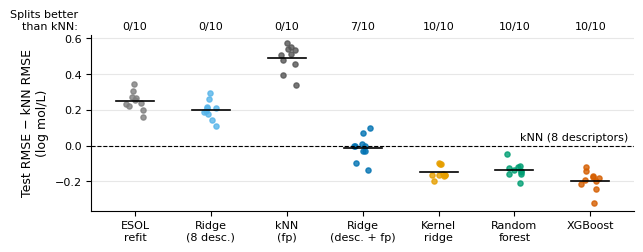

In [16]:
# Source: new figure. Scatter plot as in Tutorial 1 (6.), colours fixed per model (src/esol_evaluation.py)
plot_models = ['ESOL refit (Crippen logP)', 'Ridge (8 descriptors)', 'kNN (fingerprints)',
               'Ridge (descriptors + fingerprints)', 'Kernel ridge', 'Random forest', 'XGBoost']
short_names = ['ESOL\nrefit', 'Ridge\n(8 desc.)', 'kNN\n(fp)', 'Ridge\n(desc. + fp)', 'Kernel\nridge', 'Random\nforest',
               'XGBoost']

fig, ax = plt.subplots(figsize=(FULL_WIDTH, 2.6))
# small random shift so the 10 dots do not hide each other
rng = np.random.default_rng(RANDOM_SEED)
for i, model_name in enumerate(plot_models):
    d = comparison[comparison['model'] == model_name]['diff_vs_knn']
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=14, color=MODEL_COLOURS[model_name], alpha=0.8)
    ax.plot([i - 0.25, i + 0.25], [d.mean(), d.mean()], color='k', lw=1.2)   # mean over the 10 splits
    # number of splits better than kNN, above the plot
    ax.text(i, 1.02, f"{(d < 0).sum()}/{len(d)}", ha='center', va='bottom', fontsize=8,
            transform=ax.get_xaxis_transform())
ax.text(-0.75, 1.02, 'Splits better\nthan kNN:', ha='right', va='bottom', fontsize=8,
        transform=ax.get_xaxis_transform())
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.text(len(plot_models) - 0.5, 0.02, 'kNN (8 descriptors)', ha='right', va='bottom', fontsize=8)
ax.set_xticks(range(len(plot_models)))
ax.set_xticklabels(short_names)
ax.set_ylabel('Test RMSE \u2212 kNN RMSE\n(log mol/L)')   # \u2212 is the minus sign
ax.grid(True, axis='y', alpha=0.3)
ax.set_axisbelow(True)   # grid lines behind the points
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'models_paired_difference_vs_knn.png'), bbox_inches='tight')
plt.show()

**Observations (results against kNN)**
- The main model, XGBoost, was chosen by cross-validation only, and no test result was used for any choice (see section 2 for the timing run). Its test RMSE is 0.607 ± 0.036 (mean ± standard deviation over the 10 splits), against 0.803 ± 0.032 for kNN on the same splits. Its RMSE is lower than kNN's in 10 of 10 splits (mean difference -0.196 ± 0.056), so by our rule (at least 8 of 10) the answer to the research question is yes. The stretch goal (RMSE below 0.7) is reached in all 10 splits.
- The proposal also stated the target as kNN's RMSE of 0.77. All three models are below 0.77 in 10 of 10 splits. Their worst splits are 0.649 (XGBoost), 0.678 (kernel ridge) and 0.724 (random forest).
- The 10 test sets share molecules, so "10 of 10" is a summary of the splits, not a statistical test.
- The two secondary models also beat kNN in 10 of 10 splits, kernel ridge with 0.654 ± 0.016 and the random forest with 0.667 ± 0.032.
- Ridge, a linear model, on the same descriptors + fingerprints has a test RMSE of 0.790 ± 0.057. That is about the same as kNN (-0.013 ± 0.069, lower than kNN in 7 of 10 splits), so adding the fingerprints brings ridge from 0.997 (9 descriptors) to the level of kNN. With the same inputs, XGBoost is lower than this ridge model in 10 of 10 splits (-0.183 ± 0.041). XGBoost and ridge differ in more than being nonlinear, so the cleaner comparison is kernel ridge, which is ridge with an RBF kernel on the same inputs. It is also lower than ridge in 10 of 10 splits (-0.136 ± 0.058), so on these splits a nonlinear model helps. The fingerprints help too. They lower the RMSE of XGBoost from 0.707 to 0.607 and that of ridge from 0.997 to 0.790. The two gains overlap, so we cannot split XGBoost's lead over kNN into one part that comes from the model and one part that comes from the fingerprints.
- On average the cross-validation RMSE of the chosen models is close to their test RMSE (XGBoost 0.625 in cross-validation and 0.607 on the test sets, kernel ridge 0.660 and 0.654, random forest 0.670 and 0.667). The models in cross-validation are trained on only 4/5 of the training set, which makes the cross-validation error a little higher, so this does not prove that the choice of settings had no optimism.
- The fingerprints mostly help when they are added to the descriptors. On the 9 descriptors alone, all three models already beat kNN in 10 of 10 splits (RMSE 0.71 to 0.73), and adding the fingerprints lowers the RMSE in 10 of 10 splits for every model: by 0.039 ± 0.018 (random forest), 0.077 ± 0.020 (kernel ridge) and 0.100 ± 0.039 (XGBoost). On the fingerprints alone, the three models are worse than kNN in all 10 splits (RMSE 1.08 to 1.21).
- kNN with the Tanimoto similarity of the fingerprints (RMSE 1.29) is much worse than kNN with the 8 descriptors (0.80). In this dataset, the training molecules with the most similar substructures are a worse guide to log S than the training molecules with the most similar descriptors.
- The random forest with 9 descriptors is not clearly better than the random forest with the 8 descriptors of the proposal (difference -0.005 ± 0.015, lower in 5 of 10 splits), so the aromatic proportion adds little to the random forest. One possible reason, which we did not test, is that the number of aromatic rings is already one of the 8 descriptors and carries similar information.

## 6. Molecules with and without a descriptor twin

In `02_baselines.ipynb` (section 5), kNN's lead over the ESOL equation came mostly from test molecules with a "twin" in the training set (same 8 descriptors). Here we check whether the new models beat kNN on the molecules without a twin, where kNN cannot copy the log S of an isomer.

In [17]:
# Source: twin check of 02_baselines.ipynb (section 5), same definition (8 descriptors rounded to 6 decimals)
# Changes: for every model, with the feature set chosen by cross-validation in each split
twin_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    train_descriptors = set()
    for row in df_train[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))
    has_twin = []   # True if the test molecule's 8 descriptors are also in the training set
    for row in df_test[FEATURES].round(6).values:
        has_twin.append(tuple(row) in train_descriptors)
    has_twin = pd.Series(has_twin, index=df_test.index)

    # the test-set predictions of each model on this split (they keep the index of df_test)
    split_predictions = {
        'kNN (8 descriptors)': baseline_predictions[(baseline_predictions['seed'] == seed)
                                                    & (baseline_predictions['model'] == 'kNN (8 descriptors)')],
        'kNN (fingerprints)': predictions_df[(predictions_df['seed'] == seed) & (predictions_df['model'] == 'kNN')],
    }
    # the three proposed models, each with the feature set that cross-validation chose in this split
    for model_name in MODELS:
        chosen_row = chosen[(chosen['model'] == model_name) & (chosen['seed'] == seed)]
        feature_set = chosen_row['feature_set'].iloc[0]
        split_predictions[model_name] = predictions_df[(predictions_df['seed'] == seed)
                                                       & (predictions_df['model'] == model_name)
                                                       & (predictions_df['feature_set'] == feature_set)]

    # RMSE on the test molecules with a twin and on those without
    for model_name, pred in split_predictions.items():
        errors = pred['y_true'] - pred['y_pred']
        twin_rows.append({'seed': seed, 'model': model_name, 'n_twins': has_twin.sum(),
                          'rmse_twins': np.sqrt((errors[has_twin] ** 2).mean()),
                          'rmse_no_twin': np.sqrt((errors[~has_twin] ** 2).mean())})

twin_df = pd.DataFrame(twin_rows)
twin_df.to_csv(os.path.join(TABLE_DIR, 'models_twins.csv'), index=False)

In [18]:
# Source: paired comparison with kNN as in 02_baselines.ipynb (section 5)
# mean RMSE over the 10 splits, one row per model
twin_order = ['kNN (8 descriptors)', 'kNN (fingerprints)'] + list(MODELS)
twin_summary = twin_df.groupby('model')[['rmse_twins', 'rmse_no_twin']].mean().loc[twin_order]

# paired comparison with kNN (8 descriptors) on the same split. The kNN row stays empty
knn_twin = twin_df[twin_df['model'] == 'kNN (8 descriptors)'].set_index('seed')
for model_name in twin_order[1:]:
    runs = twin_df[twin_df['model'] == model_name].set_index('seed')
    d = runs['rmse_no_twin'] - knn_twin['rmse_no_twin']   # molecules without a twin
    twin_summary.loc[model_name, 'no_twin_diff_vs_knn'] = d.mean()
    twin_summary.loc[model_name, 'no_twin_diff_sd'] = d.std()
    twin_summary.loc[model_name, 'no_twin_wins_vs_knn'] = (d < 0).sum()
    # the same count on the molecules with a twin
    twin_summary.loc[model_name, 'twin_wins_vs_knn'] = (runs['rmse_twins'] < knn_twin['rmse_twins']).sum()
print(f"Test molecules with a twin in the training set: {twin_df['n_twins'].mean():.1f} of {len(df_test)} on average")
twin_summary.round(3)

Test molecules with a twin in the training set: 49.7 of 223 on average


,rmse_twins,rmse_no_twin,no_twin_diff_vs_knn,no_twin_diff_sd,no_twin_wins_vs_knn,twin_wins_vs_knn
model,,,,,,
kNN (8 descriptors),0.468,0.876,NaN,NaN,NaN,NaN
kNN (fingerprints),1.277,1.294,0.419,0.091,0.0,0.0
Kernel ridge,0.522,0.686,-0.189,0.045,10.0,0.0
Random forest,0.463,0.714,-0.161,0.050,10.0,7.0
XGBoost,0.419,0.651,-0.225,0.065,10.0,9.0


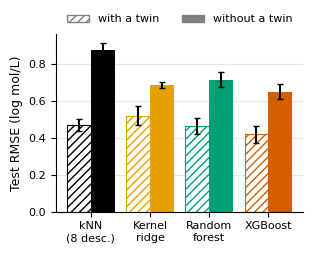

In [19]:
# Source: new figure. Bar chart as in Tutorial 4 (11.4), colours per model
# kNN on fingerprints left out (RMSE about 1.3 with and without a twin)
bar_models = ['kNN (8 descriptors)'] + list(MODELS)
twin_sd = twin_df.groupby('model')[['rmse_twins', 'rmse_no_twin']].std()   # standard deviation over the 10 splits

fig, ax = plt.subplots(figsize=(HALF_WIDTH, 2.6))
for i, model_name in enumerate(bar_models):
    colour = MODEL_COLOURS[model_name]
    # hatched bar: with a twin, filled bar: without. Error bars: SD over the splits
    ax.bar(i - 0.2, twin_summary.loc[model_name, 'rmse_twins'], width=0.4, facecolor='white',
           edgecolor=colour, hatch='////', lw=0.8, yerr=twin_sd.loc[model_name, 'rmse_twins'], capsize=2)
    ax.bar(i + 0.2, twin_summary.loc[model_name, 'rmse_no_twin'], width=0.4, color=colour,
           yerr=twin_sd.loc[model_name, 'rmse_no_twin'], capsize=2)
ax.set_xticks(range(len(bar_models)))
ax.set_xticklabels(['kNN\n(8 desc.)', 'Kernel\nridge', 'Random\nforest', 'XGBoost'])
ax.set_ylabel('Test RMSE (log mol/L)')
# legend drawn by hand, grey stands for all models
ax.legend(handles=[Patch(facecolor='white', edgecolor='grey', hatch='////', label='with a twin'),
                   Patch(color='grey', label='without a twin')], frameon=False,
          loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)   # above the plot
ax.grid(True, axis='y', alpha=0.3)
ax.set_axisbelow(True)   # grid lines behind the bars
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'models_twin_vs_no_twin.png'), bbox_inches='tight')
plt.show()

**Observations (twins)**
- On average 49.7 of the 223 test molecules have a descriptor twin in the training set.
- On the molecules without a twin, kNN has an RMSE of 0.876 and XGBoost 0.651. XGBoost's RMSE is lower in 10 of 10 splits (difference -0.225 ± 0.065), and the same is true for kernel ridge and the random forest. The new models are also better on the molecules without a twin, and the gap to kNN is largest there.
- On the molecules with a twin, XGBoost (0.419, lower than kNN in 9 of 10 splits) and the random forest (0.463, lower in 7 of 10) are about as accurate as kNN (0.468) or a bit better. Kernel ridge is less accurate (0.522) and is not lower than kNN in any split. These are only about 50 molecules per split, so the twin results are less certain than the others.
- kNN on fingerprints does equally badly with and without a twin (1.28 and 1.29). That makes sense, because its distance does not use the descriptors.

## Next notebook

`04_scaffold_split_and_uncertainty.ipynb` tests the models on molecules whose ring system is not in the training set (scaffold split) and looks at the uncertainty of the random forest and of a Gaussian process.